In [1]:
import scanpy as sc 

import pandas as pd
refAD = sc.read_h5ad("./merSubAD.h5ad")
queryAD = sc.read_h5ad("./pcfSubAD.h5ad")
refAD

AnnData object with n_obs × n_vars = 3608 × 300
    obs: 'fov', 'volume', 'center_x', 'center_y', 'min_x', 'min_y', 'max_x', 'max_y', 'anisotropy', 'transcript_count', 'perimeter_area_ratio', 'solidity', 'Anti-Chicken_raw', 'Anti-Chicken_high_pass', 'PolyT_raw', 'PolyT_high_pass', 'Cellbound2_raw', 'Cellbound2_high_pass', 'Anti-Human_raw', 'Anti-Human_high_pass', 'DAPI_raw', 'DAPI_high_pass', 'Anti-Rat_raw', 'Anti-Rat_high_pass', 'Anti-Mouse_raw', 'Anti-Mouse_high_pass', 'Cellbound3_raw', 'Cellbound3_high_pass', 'Cellbound1_raw', 'Cellbound1_high_pass', 'Anti-Goat_raw', 'Anti-Goat_high_pass', 'Anti-Rabbit_raw', 'Anti-Rabbit_high_pass', 'DAPI_raw_log', 'n_counts', 'transformed_x', 'transformed_y', 'in_ROI', 'pred_cell_type'
    var: 'n_cells', 'Symbol'

In [2]:
minX = min(refAD.obs['transformed_x'].min(), queryAD.obs['transformed_x'].min())
maxX = max(refAD.obs['transformed_x'].max(), queryAD.obs['transformed_x'].max())
minY = min(refAD.obs['transformed_y'].min(), queryAD.obs['transformed_y'].min())
maxY = max(refAD.obs['transformed_y'].max(), queryAD.obs['transformed_y'].max())
refAD.obs['New_X'] = refAD.obs['transformed_x'] - minX
refAD.obs['New_Y'] = refAD.obs['transformed_y'] - minY
queryAD.obs['New_X'] = queryAD.obs['transformed_x'] - minX
queryAD.obs['New_Y'] = queryAD.obs['transformed_y'] - minY




In [3]:
refAD.obsm['spatial'] = refAD.obs[['New_X', 'New_Y']].values
queryAD.obsm['spatial'] = queryAD.obs[['New_X', 'New_Y']].values

In [4]:
refAD.obs['CellType'] = refAD.obs['pred_cell_type']
queryAD.obs['CellType'] = queryAD.obs['cell_type']


In [5]:
import sklearn as sk 
sk.__version__

'1.3.2'

In [6]:
import scimap as sm 

import scimap as sm
refAD.obs['image_id'] = 'ref'
sm.tl.spatial_count(refAD, x_coordinate='New_X', y_coordinate='New_Y',method='knn', knn=6, phenotype='CellType', imageid='image_id')

queryAD.obs['image_id'] = 'query'
sm.tl.spatial_count(queryAD, x_coordinate='New_X', y_coordinate='New_Y',method='knn', knn=6, phenotype='CellType', imageid='image_id')

from sklearn.cluster import KMeans

# Fit KMeans on refAD.uns['spatial_count'] (n_clusters=8)
kmeans = KMeans(n_clusters=4, random_state=2025, init='random', max_iter = 1000)
kmeans.fit_predict(pd.concat([refAD.uns['spatial_count'], queryAD.uns['spatial_count']]))

ref_kmeans_labels = kmeans.predict(refAD.uns['spatial_count'])
query_kmeans_labels = kmeans.predict(queryAD.uns['spatial_count'])

refAD.obs['spatial_domain'] = ref_kmeans_labels.astype(str)
queryAD.obs['spatial_domain'] = query_kmeans_labels.astype(str)

Running SCIMAP  2.3.1
Identifying the 6 nearest neighbours for every cell
Identifying the 6 nearest neighbours for every cell


/home/adyprat/anaconda3/envs/rapids_singlecell/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning:

The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning



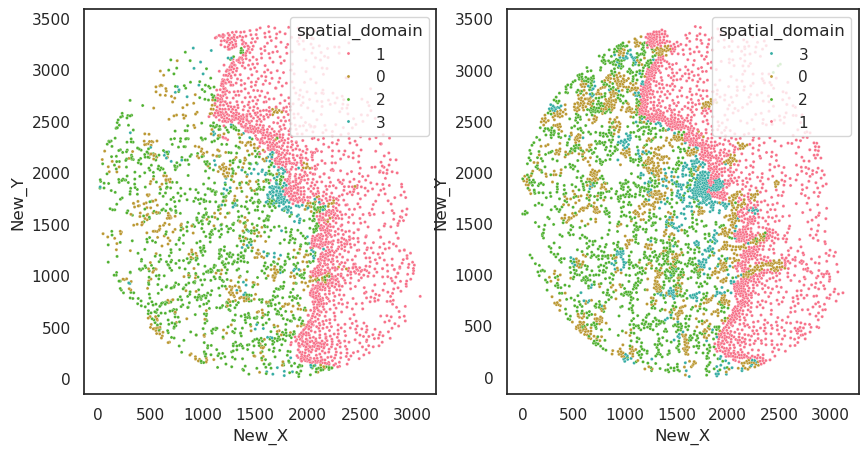

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1,2, figsize=(10, 5))
palette = sns.color_palette("husl", 6)
colorDict = {x:palette[i] for i,x in enumerate(refAD.obs['spatial_domain'].unique())}
sns.scatterplot(data=refAD.obs, x='New_X', y='New_Y', hue='spatial_domain', ax=ax[0],s=5, palette=colorDict)
sns.scatterplot(data=queryAD.obs, x='New_X', y='New_Y', hue='spatial_domain', ax=ax[1],s=5, palette=colorDict)

plt.show()


In [29]:
# Find which KRT gene has the highest total counts in refAD
krt_genes = [x for x in refAD.var_names if 'KRT' in x]
if krt_genes:
    krt_counts = {gene: refAD[:, gene].X.sum() for gene in krt_genes}
    highest_krt = max(krt_counts, key=krt_counts.get)
    print(f"KRT gene with highest total counts in refAD: {highest_krt} (total counts: {krt_counts[highest_krt]})")
else:
    print("No KRT genes found in refAD")



KRT gene with highest total counts in refAD: KRT4 (total counts: 101473)


<Axes: >

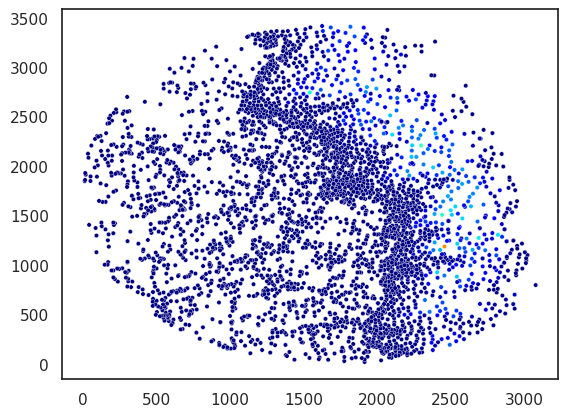

In [28]:
sns.scatterplot(x=refAD.obsm['spatial'][:,0],y=refAD.obsm['spatial'][:,1],s=10, c=refAD[:,'KRT4'].X.sum(axis=1).flatten(), cmap='jet')

In [8]:
queryAD.var_names = ['CD8', 'CD4', 'GZMB', 'Ki67', 'Histone H3 Phospho (Ser28)',
       'Galectin-3', 'HLA-A', 'CD3', 'CD45RO', 'CD45', 'CD21', 'PD-1', 'MPO',
       'CD68', 'Keratin 14', 'CD31', 'CD107', 'Podoplanin', 'SMA',
       'Collagen IV', 'CD34', 'HLA-DR', 'CD38', 'Caveolin', 'IFNG', 'VIM',
       'CD66a/c/', 'GP100', 'CD56', 'Pan-Cytokeratin']

In [9]:
prot2gene = {x:x for x in queryAD.var_names}
prot2gene['CD8'] = 'CD8A'
prot2gene['Ki67'] = 'MKI67'
prot2gene['Galectin-3'] = 'LGALS3'
prot2gene['CD3'] = 'CD3E'
prot2gene['CD45RO'] = 'PTPRC'
prot2gene['PD-1'] = 'PDCD1'
prot2gene['Keratin 14'] = 'KRT14'
prot2gene['CD31'] = 'PECAM1'
prot2gene['CD107'] = 'LAMP1'
prot2gene['Podoplanin'] = 'PDPN'
prot2gene['SMA'] = 'ACTA2'
prot2gene['Caveolin'] = 'COL1A1'
prot2gene['HLA-DR'] = 'HLA-DRA'
prot2gene['Caveolin'] = 'CAV1'
prot2gene['IFNG'] = 'IFNG'
prot2gene['VIM'] = 'VIM'
prot2gene['CD66a/c/'] = 'CEACAM1'
prot2gene['GP100'] = 'PMEL'
prot2gene['CD56'] = 'CD56'
prot2gene['Pan-Cytokeratin'] = 'KRT4'


In [10]:
queryAD.var_names = [prot2gene[x] for x in queryAD.var_names]

In [11]:
common_genes = [x for x in queryAD.var_names if x in refAD.var_names]
common_genes

['CD8A',
 'CD4',
 'GZMB',
 'MKI67',
 'LGALS3',
 'CD3E',
 'PTPRC',
 'PDCD1',
 'MPO',
 'CD68',
 'PDPN',
 'ACTA2',
 'CD34',
 'HLA-DRA',
 'CD38',
 'KRT4']

In [12]:
refSubAD = refAD[:,common_genes]
querySubAD = queryAD[:,common_genes]






In [13]:
refSubAD.obs.index = refSubAD.obs.index.values.astype(str)

/tmp/ipykernel_103207/2861514082.py:1: ImplicitModificationWarning:

Trying to modify index of attribute `.obs` of view, initializing view as actual.



In [14]:
querySubAD.obs.index

Index(['32730', '32737', '32740', '32741', '32745', '32748', '32749', '32758',
       '32766', '32767',
       ...
       '51373', '51374', '51375', '51376', '51377', '51378', '51379', '51380',
       '51381', '51383'],
      dtype='object', length=4671)

In [15]:
refSubAD

AnnData object with n_obs × n_vars = 3608 × 16
    obs: 'fov', 'volume', 'center_x', 'center_y', 'min_x', 'min_y', 'max_x', 'max_y', 'anisotropy', 'transcript_count', 'perimeter_area_ratio', 'solidity', 'Anti-Chicken_raw', 'Anti-Chicken_high_pass', 'PolyT_raw', 'PolyT_high_pass', 'Cellbound2_raw', 'Cellbound2_high_pass', 'Anti-Human_raw', 'Anti-Human_high_pass', 'DAPI_raw', 'DAPI_high_pass', 'Anti-Rat_raw', 'Anti-Rat_high_pass', 'Anti-Mouse_raw', 'Anti-Mouse_high_pass', 'Cellbound3_raw', 'Cellbound3_high_pass', 'Cellbound1_raw', 'Cellbound1_high_pass', 'Anti-Goat_raw', 'Anti-Goat_high_pass', 'Anti-Rabbit_raw', 'Anti-Rabbit_high_pass', 'DAPI_raw_log', 'n_counts', 'transformed_x', 'transformed_y', 'in_ROI', 'pred_cell_type', 'New_X', 'New_Y', 'CellType', 'image_id', 'spatial_domain'
    var: 'n_cells', 'Symbol'
    uns: 'spatial_count'
    obsm: 'spatial'

In [16]:
pd.DataFrame(refSubAD.X, index=refSubAD.obs.index.values, columns=refSubAD.var.index.values).to_csv('refSubAD_expression.csv')
pd.DataFrame(querySubAD.X, index=querySubAD.obs.index.values, columns=querySubAD.var.index.values).to_csv('querySubAD_expression.csv')

refSubAD.obs.to_csv('refSubAD_obs.csv')
querySubAD.obs.to_csv('querySubAD_obs.csv')

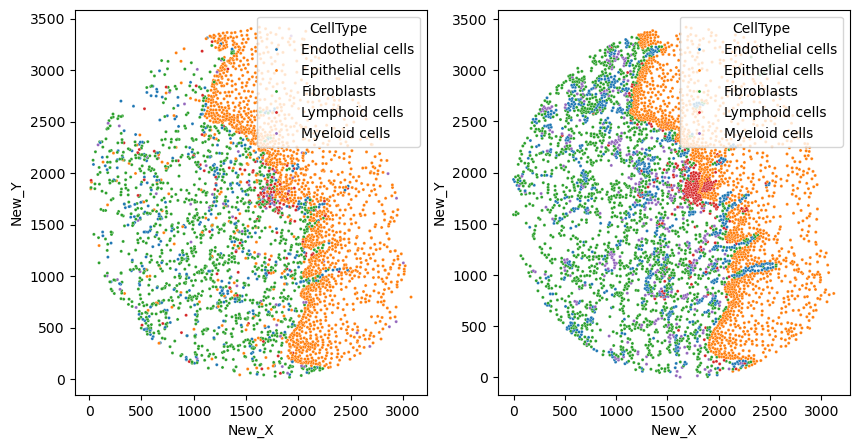

In [37]:
import seaborn as sns
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1,2, figsize=(10, 5))
sns.scatterplot(data=refAD.obs, x='New_X', y='New_Y', hue='CellType', ax=ax[0],s=5)
sns.scatterplot(data=queryAD.obs, x='New_X', y='New_Y', hue='CellType', ax=ax[1],s=5)

plt.show()


In [38]:
import seaborn as sns

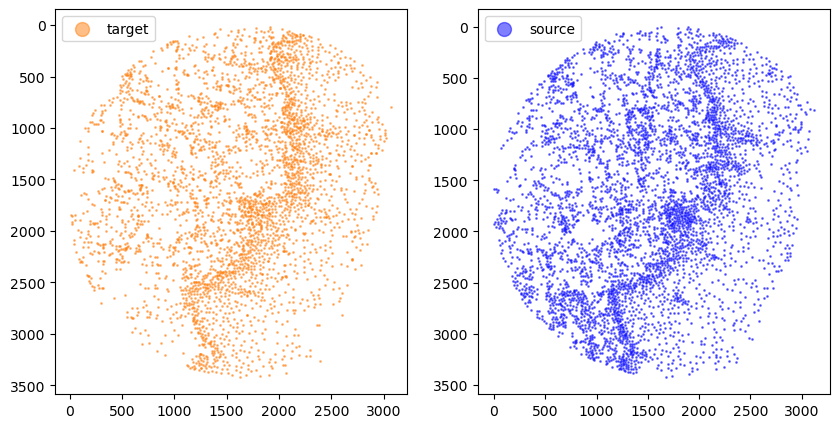

In [39]:
# xI = queryAD.obs['spot_x'].values/10
# yI = queryAD.obs['spot_y'].values/10
# xJ = refAD.obs['spot_x'].values/10
# yJ = refAD.obs['spot_y'].values/10

xI = queryAD.obs['New_X'].values
yI = queryAD.obs['New_Y'].values
xJ = refAD.obs['New_X'].values
yJ = refAD.obs['New_Y'].values
xJ = xJ.astype(int)
yJ = yJ.astype(int)
xI = xI.astype(int)
yI = yI.astype(int)
import matplotlib.pyplot as plt
fig,ax = plt.subplots(1,2, figsize=(10, 5))

ax[0].scatter(xJ,yJ,s=1,alpha=0.5,c='#ff7f0e', label='target')
ax[1].scatter(xI,yI,s=1,alpha=0.5,c='blue', label='source')
ax[0].legend(markerscale = 10)
ax[1].legend(markerscale = 10)
ax[0].invert_yaxis()
ax[1].invert_yaxis()





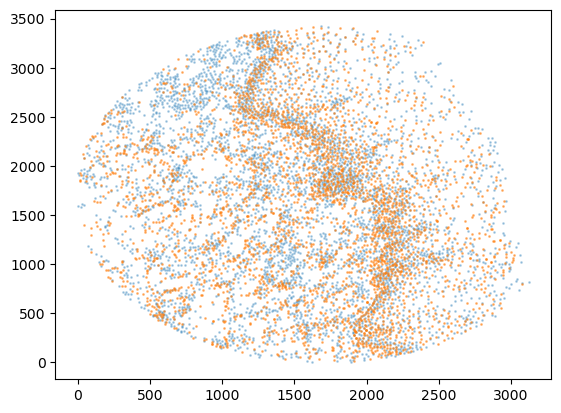

In [40]:
# plot
fig,ax = plt.subplots()
ax.scatter(xI,yI,s=1,alpha=0.3)
ax.scatter(xJ,yJ,s=1,alpha=0.5)

In [55]:
sJ = refSubAD.X
sI = querySubAD.X



In [56]:
sI.shape, sJ.shape

((4671, 16), (3608, 16))

0 of 3608
100 of 3608
200 of 3608
300 of 3608
400 of 3608
500 of 3608
600 of 3608
700 of 3608
800 of 3608
900 of 3608
1000 of 3608
1100 of 3608
1200 of 3608
1300 of 3608
1400 of 3608
1500 of 3608
1600 of 3608
1700 of 3608
1800 of 3608
1900 of 3608
2000 of 3608
2100 of 3608
2200 of 3608
2300 of 3608
2400 of 3608
2500 of 3608
2600 of 3608
2700 of 3608
2800 of 3608
2900 of 3608
3000 of 3608
3100 of 3608
3200 of 3608
3300 of 3608
3400 of 3608
3500 of 3608
3600 of 3608
3607 of 3608
0 of 4671
100 of 4671
200 of 4671
300 of 4671
400 of 4671
500 of 4671
600 of 4671
700 of 4671
800 of 4671
900 of 4671
1000 of 4671
1100 of 4671
1200 of 4671
1300 of 4671
1400 of 4671
1500 of 4671
1600 of 4671
1700 of 4671
1800 of 4671
1900 of 4671
2000 of 4671
2100 of 4671
2200 of 4671
2300 of 4671
2400 of 4671
2500 of 4671
2600 of 4671
2700 of 4671
2800 of 4671
2900 of 4671
3000 of 4671
3100 of 4671
3200 of 4671
3300 of 4671
3400 of 4671
3500 of 4671
3600 of 4671
3700 of 4671
3800 of 4671
3900 of 4671
4000 of 46

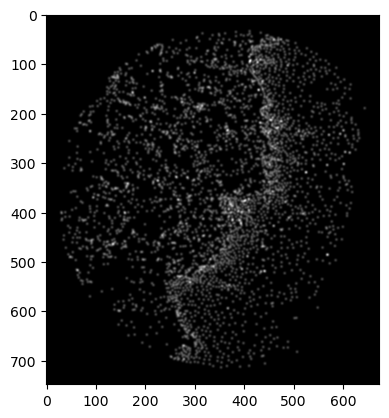

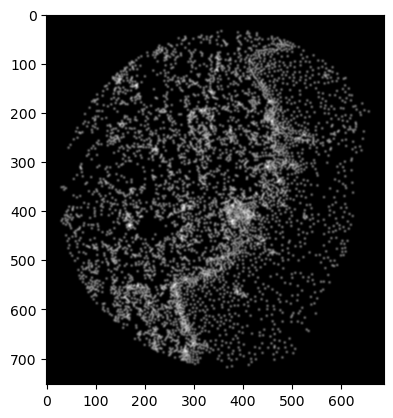

In [65]:


# XJ,YJ,J,fig = STalign.rasterize_with_signal(xJ,yJ,refSubAD.X,dx=5, draw=100)
# XI,YI,I,fig = STalign.rasterize_with_signal(xI,yI,querySubAD.X,dx=5, draw=100)


XJ,YJ,J,fig = STalign.rasterize(xJ,yJ,dx=5, draw=100)
XI,YI,I,fig = STalign.rasterize(xI,yI,dx=5, draw=100)


In [66]:
XJ.shape, J.shape, I.max()

((674,), (1, 748, 674), 0.10510663382798763)

In [67]:
# Min-max normalize I and J to 0-1
I = (I - I.min()) / (I.max() - I.min())
J = (J - J.min()) / (J.max() - J.min())


IndexError: index 2 is out of bounds for axis 0 with size 1

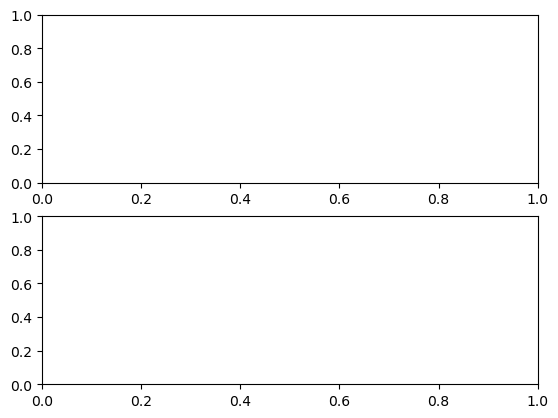

In [68]:
# get extent of images
extentI = STalign.extent_from_x((YI,XI))
extentJ = STalign.extent_from_x((YJ,XJ))

# plot rasterized images
ix = 2
fig,ax = plt.subplots(2,1)
I_sub = I[ix,:,:].squeeze()
J_sub = J[ix,:,:].squeeze()
ax[0].imshow(I_sub, extent=extentI)
ax[1].imshow(J_sub, extent=extentJ)
ax[0].invert_yaxis()
ax[1].invert_yaxis()

In [69]:
import torch # set device for building tensors
if torch.cuda.is_available():
    torch.set_default_device('cuda:0')
else:
    torch.set_default_device('cpu')

torch.cuda.is_available()

True

In [70]:
#1from STalignLDDMM import LDDMM
from STalign.STalign import LDDMM

In [76]:
Ifoo.shape

(16, 753, 687)

/home/adyprat/anaconda3/envs/rapids_singlecell/lib/python3.11/site-packages/torch/utils/_device.py:62: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return func(*args, **kwargs)


RuntimeError: Error in dlopen: /home/adyprat/anaconda3/envs/rapids_singlecell/lib/python3.11/site-packages/torch/lib/libtorch_cuda_linalg.so: undefined symbol: _ZN2at6native12DispatchStubIPFvRNS_14TensorIteratorEllENS0_18unpack_pivots_stubEE6AVX512E

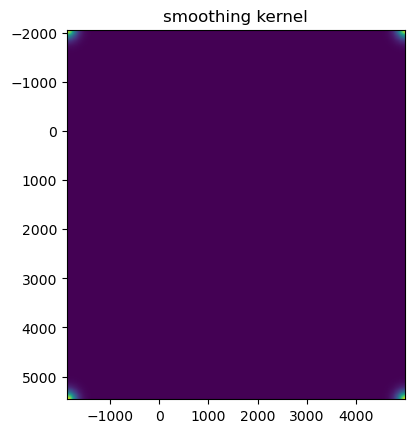

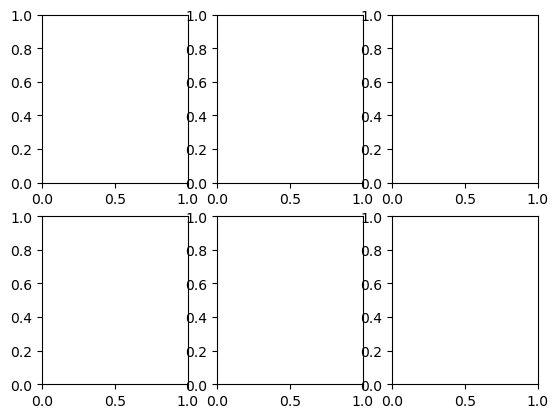

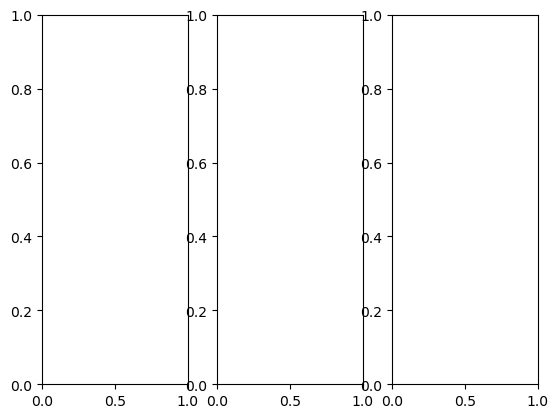

In [77]:
%%time
import numpy as np

# run LDDMM
# specify device (default device for STalign.LDDMM is cpu)
if torch.cuda.is_available():
    device = 'cuda:0'
else:
    device = 'cpu'

# keep all other parameters default
params = {
          'niter':1000,
          'device':device,
          'diffeo_start':0,
          'a':50,
          'epV':1000,
          #'muB': torch.tensor([0,0,0]), # black is background in target
          }
ix = 0
Ifoo = np.vstack((I[ix,:,:][None, ...], I[ix,:,:][None, ...], I[ix,:,:][None, ...])) # make RGB instead of greyscale
Jfoo = np.vstack((J[ix,:,:][None, ...], J[ix,:,:][None, ...], J[ix,:,:][None, ...])) # make RGB instead of greyscale

# Ifoo = I # make RGB instead of greyscale
# Jfoo = J # make RGB instead of greyscale
out = LDDMM([YI,XI],Ifoo,[YJ,XJ],Jfoo,**params)

In [43]:
I[1:4,:,:].shape

(3, 220, 217)

In [44]:
# get necessary output variables
A = out['A']
v = out['v']
xv = out['xv']

/home/adyprat/anaconda3/envs/spatial/lib/python3.8/site-packages/torch/utils/_device.py:62: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return func(*args, **kwargs)
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


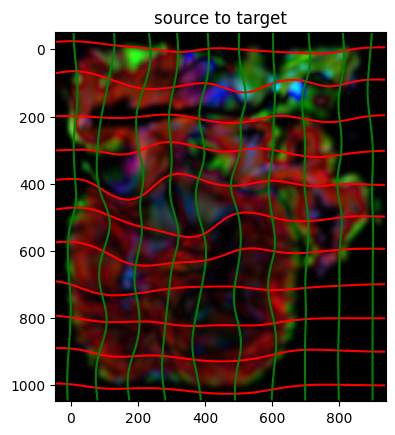

In [59]:
# apply transform
phii = STalign.build_transform(xv,v,A,XJ=[YJ,XJ],direction='b')
phiI = STalign.transform_image_source_to_target(xv,v,A,[YI,XI],Ifoo,[YJ,XJ])

#switch tensor from cuda to cpu for plotting with numpy
if phii.is_cuda:
    phii = phii.cpu()
if phiI.is_cuda:
    phiI = phiI.cpu()

# plot with grids
fig,ax = plt.subplots()
levels = np.arange(-10000,10000,100)
ax.contour(XJ,YJ,phii[...,0],colors='r',linestyles='-',levels=levels)
ax.contour(XJ,YJ,phii[...,1],colors='g',linestyles='-',levels=levels)
ax.set_aspect('equal')
ax.set_title('source to target')
ax.imshow(2*phiI[1:4,:,:].permute(1,2,0)/torch.max(phiI),extent=extentJ)

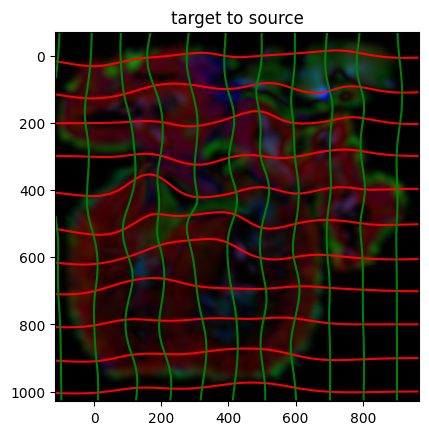

In [46]:
# apply transform
phij = STalign.build_transform(xv,v,A,XJ=[YI,XI],direction='f')
phijJ = STalign.transform_image_target_to_source(xv,v,A,[YI,XI],Jfoo,[YI,XI])

#switch tensor from cuda to cpu for plotting with numpy
if phij.is_cuda:
    phij = phij.cpu()
if phijJ.is_cuda:
    phijJ = phijJ.cpu()

# plot with grids
fig,ax = plt.subplots()
levels = np.arange(-10000,10000,100)
ax.contour(XI,YI,phij[...,0],colors='r',linestyles='-',levels=levels)
ax.contour(XI,YI,phij[...,1],colors='g',linestyles='-',levels=levels)
ax.set_aspect('equal')
ax.set_title('target to source')
ax.imshow(phijJ[1:4,:,:].permute(1,2,0)/torch.max(phijJ),extent=extentI)

In [47]:
xv_int = [t.to(torch.int) for t in xv]
xv_int

[tensor([-616, -591, -566, -541, -516, -491, -466, -441, -416, -391, -366, -341,
         -316, -291, -266, -241, -216, -191, -166, -141, -116,  -91,  -66,  -41,
          -16,    8,   33,   58,   83,  108,  133,  158,  183,  208,  233,  258,
          283,  308,  333,  358,  383,  408,  433,  458,  483,  508,  533,  558,
          583,  608,  633,  658,  683,  708,  733,  758,  783,  808,  833,  858,
          883,  908,  933,  958,  983, 1008, 1033, 1058, 1083, 1108, 1133, 1158,
         1183, 1208, 1233, 1258, 1283, 1308, 1333, 1358, 1383, 1408, 1433, 1458,
         1483, 1508, 1533, 1558], device='cuda:0', dtype=torch.int32),
 tensor([-654, -629, -604, -579, -554, -529, -504, -479, -454, -429, -404, -379,
         -354, -329, -304, -279, -254, -229, -204, -179, -154, -129, -104,  -79,
          -54,  -29,   -4,   20,   45,   70,   95,  120,  145,  170,  195,  220,
          245,  270,  295,  320,  345,  370,  395,  420,  445,  470,  495,  520,
          545,  570,  595,  620,  645,

In [48]:
# Ensure input types match grid types (FloatTensor, not DoubleTensor)
points_np = np.stack([yJ, xJ], 1).astype(np.float32)
points_tensor = torch.from_numpy(points_np).to(xv[0].device).type(xv[0].dtype)
tpointsJ  = STalign.transform_points_target_to_source(xv_int,v,A, points_tensor)


#switch from row column coordinates (y,x) to (x,y)
xJ_LDDMM = tpointsJ[:,1]
yJ_LDDMM = tpointsJ[:,0]


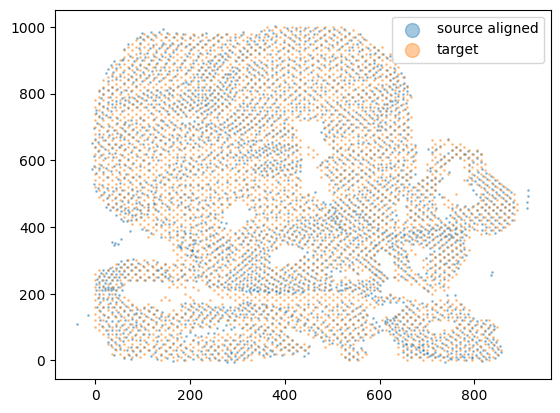

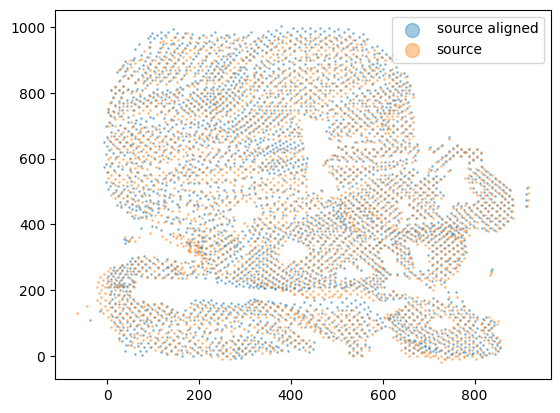

In [49]:


# Ensure input types match grid types (FloatTensor, not DoubleTensor)
points_np = np.stack([yI, xI], 1).astype(np.float32)
points_tensor = torch.from_numpy(points_np).to(xv[0].device).type(xv[0].dtype)
tpointsI = STalign.transform_points_source_to_target(
    xv, v, A, points_tensor, 
)

#switch tensor from cuda to cpu for plotting with numpy
if tpointsI.is_cuda:
    tpointsI = tpointsI.cpu()

#switch from row column coordinates (y,x) to (x,y)
xI_LDDMM = tpointsI[:,1]
yI_LDDMM = tpointsI[:,0]

# plot results
fig,ax = plt.subplots()
#ax.scatter(xJ,yJ,s=1,alpha=0.3, label='source')
ax.scatter(xI_LDDMM,yI_LDDMM,s=1,alpha=0.4, label = 'source aligned')
ax.scatter(xJ,yJ,s=1,alpha=0.4, label='target')
ax.legend(markerscale = 10)

fig,ax = plt.subplots()
ax.scatter(xI_LDDMM,yI_LDDMM,s=1,alpha=0.4, label='source aligned')
ax.scatter(xI,yI,s=1,alpha=0.4, label='source')
ax.legend(markerscale = 10)

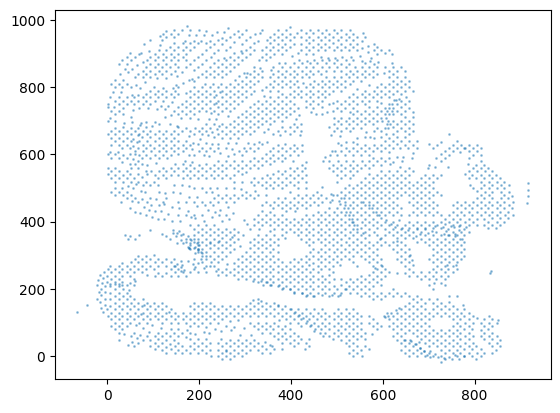

In [50]:
plt.scatter(xI,yI,s=1,alpha=0.4, label = 'source aligned')


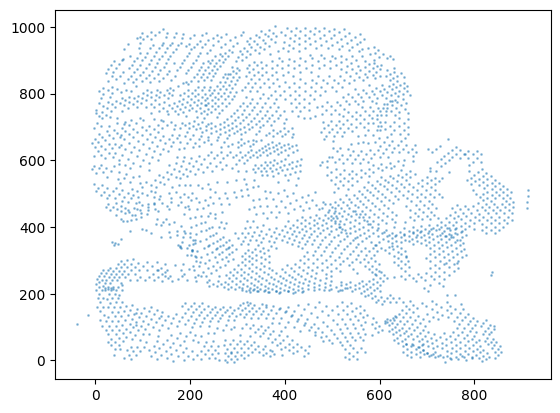

In [51]:
plt.scatter(xI_LDDMM,yI_LDDMM,s=1,alpha=0.4, label = 'source aligned')


In [52]:
xJ.shape

(3801,)

In [53]:
xJ_LDDMM.shape

torch.Size([3801])

In [54]:
queryAD

AnnData object with n_obs × n_vars = 3184 × 67
    obs: 'spot_x', 'spot_y', 'cell_count', 'Smooth muscle cells_percentage', 'Fibroblast_percentage', 'Atrial cardiomyocytes_percentage', 'Cardiomyocytes_percentage', 'Endothelium_percentage', 'Epicardium_percentage', 'Schwan progenitors_percentage', 'Ventricular cardiomyocytes_percentage', 'Cell_Num', 'New_X', 'New_Y', 'STAlign_X', 'STAlign_Y', 'CellType', 'NearestRefCellType', 'CellTypeMatch'
    var: 'mean', 'std'
    uns: 'log1p', 'pca'
    obsm: 'X_spatial', 'spatial', 'X_pca'
    varm: 'PCs'

In [55]:
queryAD.obs.loc[:, 'STAlign_X'] = xI_LDDMM
queryAD.obs.loc[:, 'STAlign_Y'] = yI_LDDMM

# Remove '_percentage' to get cell type names
cell_types = [col.replace('_percentage', '') for col in cols]

# Find the column with the maximum value for each row and assign as 'Ground Truth'
queryAD.obs['CellType'] = queryAD.obs[cols].idxmax(axis=1).str.replace('_percentage', '').astype('category')
refAD.obs['CellType'] = refAD.obs[cols].idxmax(axis=1).str.replace('_percentage', '').astype('category')



In [56]:
queryAD

AnnData object with n_obs × n_vars = 3184 × 67
    obs: 'spot_x', 'spot_y', 'cell_count', 'Smooth muscle cells_percentage', 'Fibroblast_percentage', 'Atrial cardiomyocytes_percentage', 'Cardiomyocytes_percentage', 'Endothelium_percentage', 'Epicardium_percentage', 'Schwan progenitors_percentage', 'Ventricular cardiomyocytes_percentage', 'Cell_Num', 'New_X', 'New_Y', 'STAlign_X', 'STAlign_Y', 'CellType', 'NearestRefCellType', 'CellTypeMatch'
    var: 'mean', 'std'
    uns: 'log1p', 'pca'
    obsm: 'X_spatial', 'spatial', 'X_pca'
    varm: 'PCs'

In [57]:
import numpy as np

# Assuming refAD is your reference AnnData object with 'spot_x', 'spot_y', and 'CellType' in .obs
# and queryAD is your query AnnData object with 'STAlign_X', 'STAlign_Y', and 'CellType' in .obs

# Get coordinates from refAD and queryAD
ref_coords = refAD.obs[['New_X', 'New_Y']].values
query_coords = queryAD.obs[['STAlign_X', 'STAlign_Y']].values

# Get cell types
ref_celltypes = refAD.obs['CellType'].values
query_celltypes = queryAD.obs['CellType'].values

# For each query cell, find the nearest ref cell and compare CellType
from scipy.spatial import cKDTree

tree = cKDTree(ref_coords)
dists, idxs = tree.query(query_coords, k=1)

# Compare cell types
matches = query_celltypes == ref_celltypes[idxs]

# Optionally, print or summarize the results
print(f"Number of matches: {np.sum(matches)} / {len(matches)}")
print(f"Match percentage: {np.mean(matches)*100:.2f}%")

# If you want to see which ones matched/mismatched:
queryAD.obs['NearestRefCellType'] = ref_celltypes[idxs]
queryAD.obs['CellTypeMatch'] = matches


Number of matches: 1886 / 3184
Match percentage: 59.23%


In [58]:
queryAD.obsm['X_STAlign_spatial'] = queryAD.obs[['STAlign_X', 'STAlign_Y']].values
queryAD.write_h5ad('query_STAlign.h5ad')

refAD.obsm['X_STAlign_spatial'] = refAD.obs[['New_X', 'New_Y']].values
refAD.write_h5ad('ref_STAlign.h5ad')




